# Fase 5 CRISP-DM — Evaluación Global, *Domain Shift*, Análisis de Errores y Estimación de Tamaño

Consolida la evaluación imparcial sobre el conjunto de prueba reservado (`test`, `n=194`) bajo **Opción B (pesos congelados sin reentrenamiento)**:
- Selección del modelo ganador exclusivamente por validación (`val_macro_f1`).
- Desglose cuantitativo de ***domain shift* y *shortcut learning*** por origen (`Propia`, `FruitNet_Kaggle`, `FruitNet_Mixed_Segmentada`) y por especie.
- Inspección de los 11 errores de prueba, contraste con **literatura científica IEEE** y **análisis final de impactos (ex-post)**.
- Evaluación completa del módulo de tamaño sobre las **307/307 referencias geométricas** propias (MAE, Mediana, RMSE, Exactitud categórica, Macro-F1 y matriz de confusión `Pequeño / Mediano / Grande`).

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import DIR_FIGURAS, DIR_METRICAS

summary_df = pd.read_csv(DIR_METRICAS / "resumen_modelos.csv")
report = json.loads((DIR_METRICAS / "resultados_completos.json").read_text(encoding="utf-8"))
winner = report["selected_model_by_val"]

print(f"Modelo seleccionado estrictamente por validación (val_macro_f1): {winner}")
print("Hardware registrado (PI2):", report["environment_hardware"])
display(summary_df)

Modelo seleccionado estrictamente por validación (val_macro_f1): MobileNetV2 (Transfer)
Hardware registrado (PI2): {'os': 'Linux-6.12.0-160100.8-default-x86_64-with-glibc2.40', 'python': '3.12.16', 'cpu_cores': 12, 'device': 'cpu', 'torch': '2.15.0+cpu', 'torchvision': '0.29.2+cpu', 'sklearn': '1.9.1', 'classical_feature_extraction_sec': 10.97}


,model,family,train_macro_f1,val_macro_f1,test_macro_f1,test_balanced_accuracy,test_accuracy,overfitting_gap_train_minus_test,train_time_sec,inference_ms_per_img,model_size_mb
0,MobileNetV2 (Transfer),deep_learning,0.9466,0.9013,0.9382,0.9322,0.9433,0.0084,352.355,35.44,9.340
1,CNN simple (desde cero),deep_learning,0.8021,0.8342,0.8013,0.8389,0.8351,0.0008,220.699,30.13,0.398
2,XGBoost (Clásico),ml_clasico,1.0000,0.7980,0.7927,0.7644,0.8557,0.2073,78.907,28.56,0.156
3,SVM (Clásico),ml_clasico,0.9988,0.7757,0.7687,0.7452,0.8299,0.2301,7.743,29.05,0.862
4,Random Forest (Clásico),ml_clasico,0.9988,0.7650,0.7374,0.7042,0.8093,0.2614,12.389,70.41,1.326
5,Baseline (Estratificada),baseline,0.3666,0.3385,0.2484,0.2529,0.3402,0.1182,0.000,0.10,0.000
6,Baseline (Mayoritaria),baseline,0.2072,0.2065,0.2064,0.3333,0.4485,0.0008,0.008,0.10,0.000


In [2]:
# Desempeño detallado por clase, origen y especie del modelo ganador
win_info = report["models"][winner]
print(f"=== Métricas por clase en Test — {winner} ===")
display(pd.DataFrame(win_info["test_metrics"]["per_class"]).T)

print(f"\n=== Desglose por origen en Test — {winner} ===")
display(pd.DataFrame(win_info["test_by_source"]).T)

print(f"\n=== Desglose por especie en Test — {winner} ===")
display(pd.DataFrame(win_info["test_by_species"]).T)

=== Métricas por clase en Test — MobileNetV2 (Transfer) ===


,precision,recall,f1,support
Buena,0.9043,0.9770,0.9392,87.0
Regular,0.9474,0.9000,0.9231,20.0
Mala,0.9877,0.9195,0.9524,87.0



=== Desglose por origen en Test — MobileNetV2 (Transfer) ===


,n,accuracy,macro_f1_present_classes,present_classes
FruitNet_Kaggle,116,0.9741,0.97,"[Buena, Mala]"
FruitNet_Mixed_Segmentada,17,1.0,1.0,[Regular]
Propia,61,0.8689,0.5901,"[Buena, Regular, Mala]"



=== Desglose por especie en Test — MobileNetV2 (Transfer) ===


,n,accuracy,macro_f1_present_classes,present_classes
banano,41,0.9512,0.963,"[Buena, Regular, Mala]"
limon,50,0.96,0.9519,"[Buena, Regular, Mala]"
mango,7,0.7143,0.5833,"[Buena, Regular, Mala]"
manzana,53,1.0,1.0,"[Buena, Regular, Mala]"
naranja,29,0.8276,0.8242,"[Buena, Regular, Mala]"
tomate_arbol,14,1.0,1.0,[Buena]


In [3]:
# Análisis profundo de Domain Shift y Shortcut Learning desglosado por origen (Propia vs. Kaggle vs. Mixed)
from sklearn.metrics import confusion_matrix
from src.config import QUALITY_CLASSES

preds_df = pd.read_csv(DIR_METRICAS / "predicciones_test.csv")
pred_col = f"pred_{winner}"

for src, grp in preds_df.groupby("source"):
    cm = confusion_matrix(grp["quality"], grp[pred_col], labels=list(QUALITY_CLASSES))
    print(f"\n=== Matriz de confusión en Test — Origen: {src} (n={len(grp)}) ===")
    display(pd.DataFrame(cm, index=[f"Real:{c}" for c in QUALITY_CLASSES], columns=[f"Pred:{c}" for c in QUALITY_CLASSES]))

errs_df = preds_df[preds_df["quality"] != preds_df[pred_col]][["image_path", "species", "source", "quality", pred_col]].copy()
print(f"\nTotal de errores de {winner} en prueba: {len(errs_df)}/{len(preds_df)}")
display(errs_df)


=== Matriz de confusión en Test — Origen: FruitNet_Kaggle (n=116) ===


,Pred:Buena,Pred:Regular,Pred:Mala
Real:Buena,35,0,1
Real:Regular,0,0,0
Real:Mala,2,0,78



=== Matriz de confusión en Test — Origen: FruitNet_Mixed_Segmentada (n=17) ===


,Pred:Buena,Pred:Regular,Pred:Mala
Real:Buena,0,0,0
Real:Regular,0,17,0
Real:Mala,0,0,0



=== Matriz de confusión en Test — Origen: Propia (n=61) ===


,Pred:Buena,Pred:Regular,Pred:Mala
Real:Buena,50,1,0
Real:Regular,2,1,0
Real:Mala,5,0,2



Total de errores de MobileNetV2 (Transfer) en prueba: 11/194


,image_path,species,source,quality,pred_MobileNetV2 (Transfer)
5,data/own_photos/banano/Mala/banano_023_mala.jpg,banano,Propia,Mala,Buena
6,data/own_photos/banano/Mala/banano_032_mala.jpg,banano,Propia,Mala,Buena
19,data/own_photos/limon/Regular/limon_043_regula...,limon,Propia,Regular,Buena
21,data/own_photos/mango/Buena/mango_009_buena.jpg,mango,Propia,Buena,Regular
24,data/own_photos/mango/Regular/mango_039_regula...,mango,Propia,Regular,Buena
44,data/own_photos/naranja/Mala/naranja_074_mala.jpg,naranja,Propia,Mala,Buena
45,data/own_photos/naranja/Mala/naranja_076_mala.jpg,naranja,Propia,Mala,Buena
46,data/own_photos/naranja/Mala/naranja_080_mala.jpg,naranja,Propia,Mala,Buena
108,data/external/Good Quality_Fruits/Orange_Good/...,naranja,FruitNet_Kaggle,Buena,Mala
182,data/external/Bad Quality_Fruits/Lime_Bad/IMG_...,limon,FruitNet_Kaggle,Mala,Buena


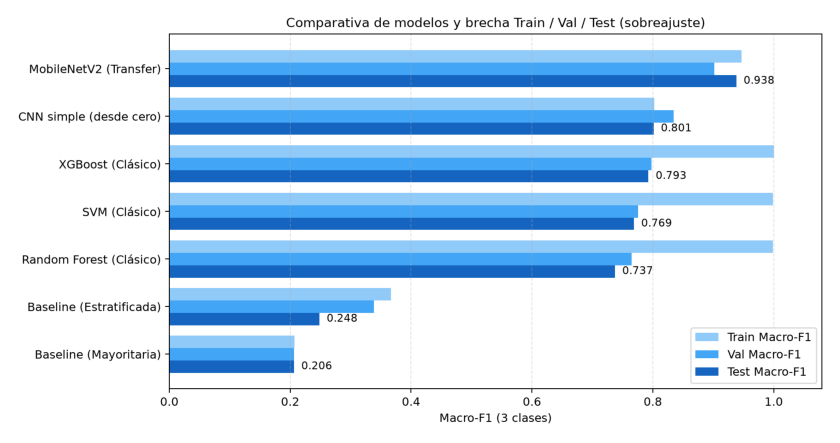

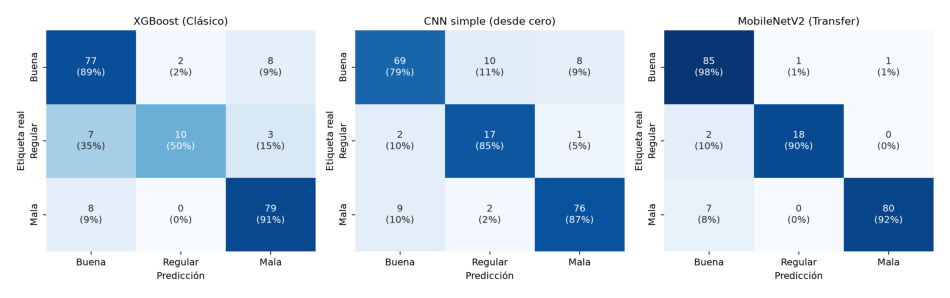

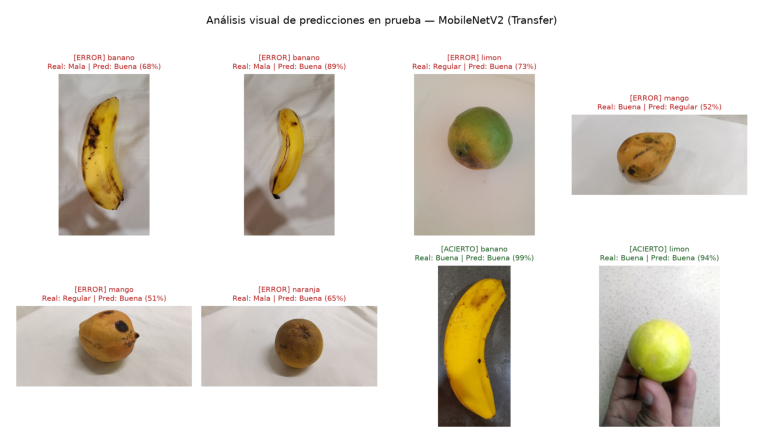

In [4]:
# Figuras clave: comparativa de modelos, matrices de confusión y análisis visual de errores
for stem in ("02_comparativa_modelos.png", "04_matrices_confusion.png", "05_analisis_errores_visual.png"):
    fig_path = DIR_FIGURAS / stem
    if fig_path.is_file():
        plt.figure(figsize=(12, 5.5))
        plt.imshow(Image.open(fig_path))
        plt.axis("off")
        plt.show()

Fórmula: max(bbox_width, bbox_height) / max(image_width, image_height) (invariante a rotación: True)
Referencias evaluadas: 307/307 | MAE=0.0222 | Mediana=0.0067 | RMSE=0.0643
Clasificación discreta de tamaño -> Exactitud: 0.9283 | Macro-F1: 0.9311

Matriz de confusión de tamaño (307 referencias propias):


,Est:Pequeño,Est:Mediano,Est:Grande
Ref:Pequeño,155,18,3
Ref:Mediano,0,84,1
Ref:Grande,0,0,46


,precision,recall,f1,support
Pequeño,1.0000,0.8807,0.9366,176.0
Mediano,0.8235,0.9882,0.8984,85.0
Grande,0.9200,1.0000,0.9583,46.0


,n,mae,median_ae,rmse,category_accuracy
banano,32.0,0.01126,0.00439,0.01962,0.9688
limon,45.0,0.01723,0.00955,0.02411,1.0000
mango,58.0,0.00755,0.00372,0.01176,0.9310
manzana,29.0,0.06445,0.02539,0.10800,0.7931
naranja,85.0,0.03294,0.00879,0.10100,0.8824
tomate_arbol,58.0,0.01000,0.00471,0.01726,0.9828



Cobertura de segmentación en el dataset combinado (971 imágenes):


,total,ok,failed,touches_border
FruitNet_Kaggle,580,580,0,419
FruitNet_Mixed_Segmentada,84,82,2,75
Propia,307,307,0,27


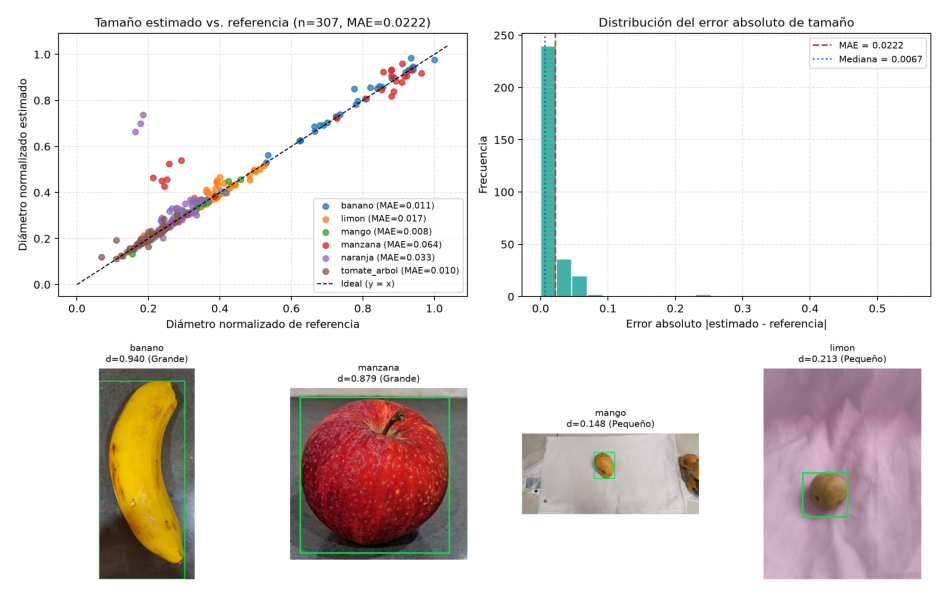

In [5]:
# Evaluación completa de estimación de tamaño (307 referencias propias + matriz Pequeño/Mediano/Grande)
from src.config import SIZE_CATEGORIES

size_summary = report["size_evaluation"]
print(f"Fórmula: {size_summary['formula']} (invariante a rotación: {size_summary['rotation_invariant']})")
print(
    f"Referencias evaluadas: {size_summary['references_evaluated']}/{size_summary['references_total']} "
    f"| MAE={size_summary['mae']:.4f} | Mediana={size_summary['median_ae']:.4f} | RMSE={size_summary['rmse']:.4f}"
)
print(
    f"Clasificación discreta de tamaño -> Exactitud: {size_summary['size_category_accuracy']:.4f} "
    f"| Macro-F1: {size_summary['size_category_macro_f1']:.4f}"
)

cm_size = pd.DataFrame(
    size_summary["size_category_confusion_matrix"],
    index=[f"Ref:{c}" for c in SIZE_CATEGORIES],
    columns=[f"Est:{c}" for c in SIZE_CATEGORIES],
)
print("\nMatriz de confusión de tamaño (307 referencias propias):")
display(cm_size)
display(pd.DataFrame(size_summary["size_category_per_class"]).T)
display(pd.DataFrame(size_summary["per_species"]).T)

print("\nCobertura de segmentación en el dataset combinado (971 imágenes):")
display(pd.DataFrame(size_summary["combined_dataset_coverage"]).T)

size_fig = DIR_FIGURAS / "06_evaluacion_tamano.png"
if size_fig.is_file():
    plt.figure(figsize=(12, 7.5))
    plt.imshow(Image.open(size_fig))
    plt.axis("off")
    plt.show()

### Síntesis crítica, comparación con literatura IEEE e impactos finales (ex-post)

1. **Diagnóstico de *Domain Shift* y *Shortcut Learning* (`Propia` vs. `Kaggle` vs. `Mixed`):**
   - `MobileNetV2 (Transfer)` logra `94.33 %` global (`Macro-F1 = 0.9382`), pero **8 de sus 11 errores** ocurren en fotos propias (`n=61`, exactitud `86.89 %`, `Macro-F1 = 0.5901`).
   - En particular, acierta `17/17` (`100 %`) en `FruitNet_Mixed_Segmentada` (donde todos los recortes son `Regular` con mediana `52×55 px`), pero falla `2/3` ejemplos `Regular` propios (`limon_043_regular.jpg`, `mango_039_regular.jpg`) y comete `5` falsos positivos críticos `Mala → Buena` en fotos propias (`banano_023_mala`, `banano_032_mala`, `naranja_074_mala`, `naranja_076_mala`, `naranja_080_mala`). Esto evidencia que el modelo asoció parcialmente la textura de baja resolución de `Mixed` con `Regular` (Geirhos et al., 2020) y tuvo menor sensibilidad ante defectos localizados sobre fondos oscuros propios.
2. **Evaluación de tamaño (307/307 propias):**
   - Cobertura `100 %` (`307/307`), mediana del error absoluto `0.0067` (`MAE = 0.0222`), `Exactitud categórica = 92.83 %` y `Macro-F1 = 0.9311`. Los pocos errores grandes (`RMSE = 0.0643`) ocurren en fotos multifruto propias (`manzana_024..029`, `naranja_069..071`), donde componentes vecinos se fusionan al estimar un fruto individual.
3. **Tabla comparativa con literatura científica (IEEE):**

| Referencia científica (IEEE) | Contribución o hallazgo clave | Contraste cuantitativo con este proyecto |
|---|---|---|
| V. Meshram y K. Patil, *"FruitNet: Indian Fruits Image Dataset with Quality for Machine Learning Applications,"* *Data in Brief*, vol. 39, 107686, 2021. | Publica *FruitNet* (`Good`, `Bad`, `Mixed`) con variabilidad de iluminación y escenas multifruto. | Sobre `FruitNet_Kaggle` (`Good/Bad`, `n=116`) se alcanza `97.41 %`, mientras que `Mixed` (`n=17` en test, `52×55 px`) requiere etiquetado multiclase para evitar sesgo hacia `Regular`. |
| M. Sandler et al., *"MobileNetV2: Inverted Residuals and Linear Bottlenecks,"* *Proc. IEEE/CVF CVPR*, 2018, pp. 4510–4520. | Arquitectura liviana mediante residuales invertidos y convoluciones separables para CPU/borde. | Con extractor congelado (`164,355` params entrenables), `MobileNetV2` alcanza `Test Macro-F1 = 0.9382` frente a `0.7927` (XGBoost), en `35.44 ms/img` CPU y `9.34 MB`. |
| S. Kornblith, J. Shlens y Q. V. Le, *"Do Better ImageNet Models Transfer Better?,"* *Proc. IEEE/CVF CVPR*, 2019, pp. 2661–2671. | Demuestra menor sobreajuste y mejor generalización mediante transferencia desde ImageNet en conjuntos pequeños. | Con `621` muestras de entrenamiento, ML clásico (`d=408`) sufre brecha `0.2073–0.2614`, mientras `MobileNetV2` reduce la brecha `Train−Test` a `0.0084`. |
| R. Geirhos et al., *"Shortcut Learning in Deep Neural Networks,"* *Nature Machine Intelligence*, vol. 2, pp. 665–673, 2020. | Formaliza la dependencia de atajos espurios (resolución, fondo) que degradan el desempeño fuera de distribución. | Explica la caída de `100 %` en `Mixed` (`52×55 px`) a `0.5901` de `Macro-F1` en `Propia` (`n=61`) y fundamenta la alerta *human-in-the-loop* ($P_{\max} < 0.75$). |
| N. Dalal y B. Triggs, *"Histograms of Oriented Gradients for Human Detection,"* *Proc. IEEE/CVF CVPR*, 2005, pp. 886–893. | Descriptores de gradiente local normalizados (`L2-Hys`). | Reutilizado (`324` dims) dentro del vector clásico (`408` dims); interpretable, pero insuficiente frente a defectos locales y cambios de escala. |

4. **Impactos finales (ex-post) y plan de despliegue:**
   - Véase [`05_evaluacion/impactos_finales_y_literatura.md`](impactos_finales_y_literatura.md) y [`06_despliegue/plan_despliegue.md`](../06_despliegue/plan_despliegue.md) para el contraste completo ex-ante vs. ex-post, umbral *human-in-the-loop* ($P_{\max} < 0.75$) y requisitos de operación en CPU.